In [ ]:
# Install required packages
!pip install -q torch_geometric
!pip install -q pynndescent
!pip install -q scanpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 19.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 44.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.1/169.1 kB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.7/37.7 MB 21.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.2/58.2 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 254.1/254.1 kB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 106.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.7/53.7 kB 4.2 MB/s eta 0:00:00


In [ ]:
# Import modules
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import anndata as ad
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
import torch_geometric
from torch_geometric.nn import GATConv
import pynndescent
from scipy import sparse as sp
from tqdm import tqdm
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report

In [ ]:
# Mount drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Load data

In [ ]:
# Load MERFISH AnnData
adata_st = sc.read_h5ad('/content/drive/My Drive/Colab Notebooks/NNDL Project/data/moffit_spatial_train.h5ad')
adata_st

AnnData object with n_obs × n_vars = 10000 × 155
    obs: 'Cell_ID', 'Animal_ID', 'Animal_sex', 'Behavior', 'Bregma', 'Centroid_X', 'Centroid_Y', 'Cell_class', 'Neuron_cluster_ID', 'batch'
    var: 'mean', 'std'
    uns: 'Cell_class_colors', 'log1p'
    obsm: 'spatial', 'spatial3d'

In [ ]:
# Load sc data
adata_sc = sc.read_h5ad('/content/drive/My Drive/Colab Notebooks/NNDL Project/data/moffit_scRNA_train.h5ad')
adata_sc

AnnData object with n_obs × n_vars = 28390 × 155
    obs: 'Sex', 'Replicate_number', 'Cell_class', 'Non-neuronal_cluster_ID', 'Neuronal_cluster_ID'
    var: 'mean', 'std'
    uns: 'log1p'

# Dataset and DataLoader
Dataset classes are modified to return labels for each sample:

In [ ]:
def get_knn(location, n_neighbors):
    index = pynndescent.NNDescent(location, n_neighbors=n_neighbors)
    neighbor_idx, neighbor_dist = index.neighbor_graph
    return neighbor_idx, neighbor_dist

def knn_to_adj(knn_idx, knn_dist):

    n_samples, n_neighbors = knn_idx.shape

    row = np.repeat(np.arange(n_samples), n_neighbors)
    col = knn_idx.flatten()
    data = np.ones(n_samples * n_neighbors)

    adj_matrix = sp.csr_matrix((data, (row, col)), shape=(n_samples, n_samples))
    return adj_matrix

def location_to_edge(location, n_neighbors):
    idx, dist = get_knn(location, n_neighbors)
    adj = knn_to_adj(idx, dist)
    edge = torch_geometric.utils.from_scipy_sparse_matrix(adj)[0]
    return edge

In [ ]:
class spatialDataset(Dataset):
    def __init__(self, data_fit, location, labels=None):
        data_fit = data_fit.toarray() if sp.issparse(data_fit) else data_fit
        assert len(data_fit) == len(location)
        if labels is not None:
            assert len(data_fit) == len(labels)

        self.data_fit = data_fit
        self.location = location
        self.labels = labels

    def __len__(self):
        return len(self.data_fit)

    def __getitem__(self, index):
        if self.labels is not None:
            return self.data_fit[index], self.location[index], self.labels[index]
        else:
            return self.data_fit[index], self.location[index]


class rnaDataset(Dataset):
    def __init__(self, data_fit, labels):
        self.data_fit = data_fit.toarray() if sp.issparse(data_fit) else data_fit
        self.labels = labels

    def __len__(self):
        return len(self.data_fit)

    def __getitem__(self, index):
        x = torch.tensor(self.data_fit[index], dtype=torch.float32)
        y = torch.tensor(self.labels[index], dtype=torch.long)
        return x, y



class spatialCollate():
    def __init__(self, knn=10, device=None):
        self.knn = knn
        # self.knn = min(knn, len(locations) - 1)  # to avoid missing neighbours

        self.device = device or ('cuda' if torch.cuda.is_available() else 'cpu')

    def __call__(self, batch):
        # Check if labels are in batch
        if len(batch[0]) == 3:
            data_list, location_list, label_list = zip(*batch)
            label_tensor = torch.as_tensor(label_list, dtype=torch.long, device=self.device)
        else:
            data_list, location_list = zip(*batch)
            label_tensor = None

        data_tensor = torch.as_tensor(np.vstack(data_list), dtype=torch.float32, device=self.device)
        locations = np.vstack(location_list)
        edge_index = location_to_edge(locations, self.knn).to(self.device)

        return data_tensor, edge_index, label_tensor


# Model definition

## Encoders

In [ ]:
class EncoderSC(nn.Module):
    def __init__(self, d_input, d_hidden, d_latent, dropout=0.0):
        super().__init__()
        self.d_input = d_input
        self.d_latent = d_latent
        self.d_hidden = d_hidden
        self.model = nn.Sequential(nn.Linear(d_input, d_hidden),
                                   nn.ReLU(),
                                   nn.Dropout(dropout),
                                   nn.Linear(d_hidden, d_hidden),
                                   nn.ReLU(),
                                   nn.Linear(d_hidden, d_latent))
        for module in self.modules():
            if isinstance(module, nn.Linear):
                torch.nn.init.normal_(module.weight, mean=0, std=0.1)
                torch.nn.init.normal_(module.bias, mean=0, std=0.1)

    def forward(self, x):
        z = self.model(x)
        return z

class GATLayer(nn.Module):
    def __init__(self, d_input, num_heads=4, n_layers=1, dropout=0.0, residual=True):
        super().__init__()
        self.residual = residual
        self.num_heads = num_heads
        self.conv_layers = nn.ModuleList()
        self.n_layers = n_layers

        for i in range(self.n_layers):
            self.conv_layers.append(GATConv(d_input, d_input, heads=num_heads, concat=False))

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, edge_index):
        if self.residual:
            resid = x
        for layer in self.conv_layers:
            x = layer(x, edge_index)
            x = self.dropout(F.leaky_relu(x))
        if self.residual:
            x += resid
        return x

class EncoderST(nn.Module):
    def __init__(self, d_input, d_hidden, d_latent, num_heads=1, n_layers=1, dropout=0.0, residual=True):
        super().__init__()

        self.pre_fc = nn.Sequential(nn.Linear(d_input, d_hidden, bias=True),
                                    nn.ReLU(),
                                    nn.Dropout(dropout),
                                    nn.Linear(d_hidden, d_latent, bias=True))
        self.post_fc = nn.Linear(d_latent, d_latent, bias=True)
        self.gat_layer = GATLayer(d_input=d_latent, num_heads=num_heads, n_layers=n_layers, dropout=dropout, residual=residual)

    def forward(self, x, e):
        z = self.pre_fc(x)
        z = self.gat_layer(z, e)
        z = self.post_fc(z)

        return z

## Classifer

A simple MLP classifier is built to test cross-modal inference.

In [ ]:
class Classifier(nn.Module):

    def __init__(self, d_input, d_hidden, n_classes):
        super().__init__()
        self.model = nn.Sequential(nn.Linear(d_input, d_hidden),
                                   nn.LeakyReLU(),
                                   nn.Linear(d_hidden, n_classes))

    def forward(self, x):
        return self.model(x)

## Full Model

In [ ]:
class CrossClassifier(nn.Module):
    def __init__(self,
                 input_dim,         # shared input dimension
                 d_hidden,
                 d_latent,
                 classifier_hidden,
                 n_classes,
                 num_heads=1,
                 n_layers=1,
                 dropout=0.0,
                 residual=True):
        super().__init__()

        # Shared-dim encoders
        self.SC_encoder = EncoderSC(d_input=input_dim,
                                     d_hidden=d_hidden,
                                     d_latent=d_latent,
                                     dropout=dropout)

        self.ST_encoder = EncoderST(d_input=input_dim,
                                    d_hidden=d_hidden,
                                    d_latent=d_latent,
                                    num_heads=num_heads,
                                    n_layers=n_layers,
                                    dropout=dropout,
                                    residual=residual)

        # Freeze encoders
        for p in self.SC_encoder.parameters():
            p.requires_grad = False
        for p in self.ST_encoder.parameters():
            p.requires_grad = False

        # Classifier on top of latent space
        self.classifier = Classifier(d_input=d_latent,
                                     d_hidden=classifier_hidden,
                                     n_classes=n_classes)

        self.clf_loss = nn.CrossEntropyLoss()


    def forward(self, x, edge_index=None, use_sc=False):
        """
        - During training: uses SC encoder (no graph)
        - During eval: uses ST encoder (with graph)
        """
        if self.training or use_sc:  # built-in attribute and input
            latent = self.SC_encoder(x)  # encode scrna data
        else:
            if edge_index is None:
                raise ValueError("Must provide edge_index during evaluation for ST data.")
            latent = self.ST_encoder(x, edge_index)  # encode spatial data

        return self.classifier(latent)


# Model Training



In [ ]:
# OHE labels
le = LabelEncoder()
adata_sc.obs['Label_idx'] = le.fit_transform(adata_sc.obs['Cell_class'])  # training set
adata_st.obs['Label_idx'] = le.transform(adata_st.obs['Cell_class'])  # test set


In [ ]:
adata_sc.obs['Label_idx'].unique()

array([2, 4, 5, 0, 3, 6, 1])

In [ ]:
adata_st.obs['Label_idx'].unique()

array([3, 4, 2, 5, 0, 6, 1])

## Training loop
 The training process is monitored with the validation loss and classification metrics.

In [ ]:
# device
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Training parameters
num_epoch = 200
log_every_n_epochs = 10

# Datasets preparation
spatial_batchsize = 32
rna_batchsize = 64


# SC train/val data
X_sc = adata_sc.X
y_sc = adata_sc.obs["Label_idx"].values

full_dataset = rnaDataset(X_sc, y_sc)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = torch.utils.data.random_split(full_dataset, [train_size, val_size])
train_loader = DataLoader(train_dataset, batch_size=rna_batchsize, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=rna_batchsize, shuffle=False)

# Spatial test data
X_spatial = adata_st.X
edge_index = adata_st.obsm["spatial"]
y_spatial = adata_st.obs["Label_idx"].values

test_dataset = spatialDataset(X_spatial, edge_index, y_spatial)
test_loader = DataLoader(test_dataset, batch_size=spatial_batchsize, collate_fn=spatialCollate(knn=10), shuffle=False)


In [ ]:
# Set seeds
torch.manual_seed(42)
np.random.seed(42)


# Model instance
model = CrossClassifier(
    input_dim=adata_sc.shape[1],  # number of shared genes
    d_hidden=64,
    d_latent=32,
    dropout=0.1,
    classifier_hidden=64,
    n_classes=len(adata_sc.obs['Cell_class'].unique()),  # number of shared cell types
    )


# Pretrained encoders
model_path = '/content/drive/My Drive/Colab Notebooks/NNDL Project/models_checkpoints/'

# Load weights into submodules directly
model.ST_encoder.load_state_dict(torch.load(model_path + 'spatial_encoder_weights_finetuned.pth', map_location=torch.device('cpu')))
model.SC_encoder.load_state_dict(torch.load(model_path + 'scrna_encoder_weights_finetuned.pth', map_location=torch.device('cpu')))

# Set encoders to evalutation for dropout behaviour
model.ST_encoder.eval()
model.SC_encoder.eval()

# Set optmizier
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Move to device
model.to(device)

CrossClassifier(
  (SC_encoder): EncoderSC(
    (model): Sequential(
      (0): Linear(in_features=155, out_features=64, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=64, out_features=64, bias=True)
      (4): ReLU()
      (5): Linear(in_features=64, out_features=32, bias=True)
    )
  )
  (ST_encoder): EncoderST(
    (pre_fc): Sequential(
      (0): Linear(in_features=155, out_features=64, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=64, out_features=32, bias=True)
    )
    (post_fc): Linear(in_features=32, out_features=32, bias=True)
    (gat_layer): GATLayer(
      (conv_layers): ModuleList(
        (0): GATConv(32, 32, heads=1)
      )
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (classifier): Classifier(
    (model): Sequential(
      (0): Linear(in_features=32, out_features=64, bias=True)
      (1): LeakyReLU(negative_slope=0.01)
      (2): Linear(in_feature

In [ ]:
# Loop
n_epochs = 350
log_every_n_epochs = 50

train_losses, val_losses = [], []
train_accuracies = []
val_accuracies, val_f1s = [], []

for epoch in range(n_epochs):
    model.train()
    total_loss = 0
    all_preds, all_labels = [], []

    for x, y in tqdm(train_loader, desc=f"Epoch {epoch+1}/{n_epochs}", leave=False):
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        logits = model(x)
        loss = F.cross_entropy(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(y)
        all_preds.append(logits.argmax(1).detach().cpu())
        all_labels.append(y.detach().cpu())

    train_loss = total_loss / len(train_loader.dataset)
    train_acc = accuracy_score(torch.cat(all_labels), torch.cat(all_preds))

    # Validation
    model.eval()
    val_loss, val_preds, val_labels = 0, [], []

    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            logits = model(x, use_sc=True)  # force SC_encoder for validation
            val_loss += F.cross_entropy(logits, y).item() * len(y)
            val_preds.append(logits.argmax(1).cpu())
            val_labels.append(y.cpu())

    val_loss /= len(val_loader.dataset)
    val_preds = torch.cat(val_preds)
    val_labels = torch.cat(val_labels)
    val_acc = accuracy_score(val_labels, val_preds)
    val_f1 = f1_score(val_labels, val_preds, average='macro')

    # Logging
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)
    val_f1s.append(val_f1)

    if (epoch + 1) % log_every_n_epochs == 0:
        print(f"[Epoch {epoch+1}] Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | F1: {val_f1:.4f}")

[Epoch 50] Train Loss: 0.1068 | Train Acc: 0.9653 | Val Loss: 0.1140 | Val Acc: 0.9678 | F1: 0.9131


[Epoch 100] Train Loss: 0.0940 | Train Acc: 0.9683 | Val Loss: 0.1086 | Val Acc: 0.9695 | F1: 0.9109


[Epoch 150] Train Loss: 0.0834 | Train Acc: 0.9712 | Val Loss: 0.1177 | Val Acc: 0.9660 | F1: 0.9360


[Epoch 200] Train Loss: 0.0816 | Train Acc: 0.9730 | Val Loss: 0.1118 | Val Acc: 0.9678 | F1: 0.9261


[Epoch 250] Train Loss: 0.0778 | Train Acc: 0.9737 | Val Loss: 0.1152 | Val Acc: 0.9697 | F1: 0.9279


[Epoch 300] Train Loss: 0.0771 | Train Acc: 0.9742 | Val Loss: 0.1336 | Val Acc: 0.9648 | F1: 0.9250


[Epoch 350] Train Loss: 0.0778 | Train Acc: 0.9733 | Val Loss: 0.1247 | Val Acc: 0.9697 | F1: 0.9164


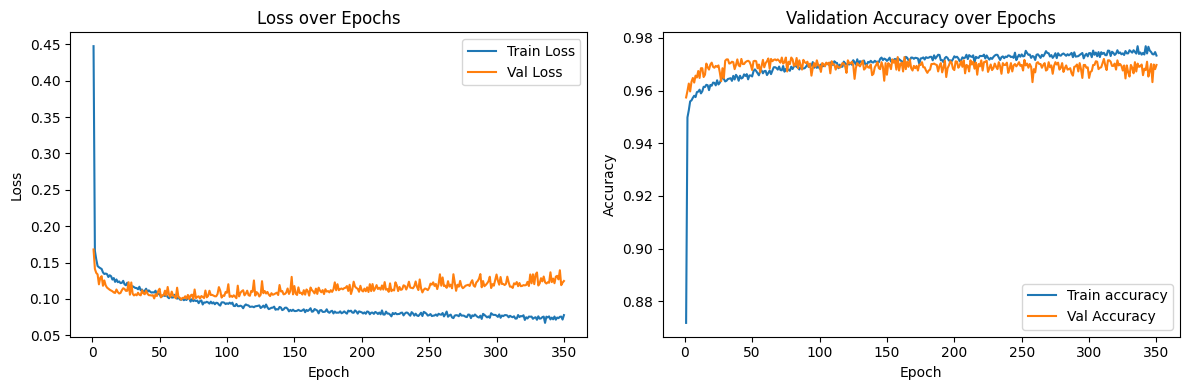

In [ ]:
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(12, 4))

# Losses
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss over Epochs")
plt.legend()

# Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, label="Train accuracy")
plt.plot(epochs, val_accuracies, label="Val Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy over Epochs")
plt.legend()

plt.tight_layout()
plt.show()

# Model Testing

In [ ]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for x, edge_index, y in test_loader:  # or whatever your loader yields
        x, y = x.to(device), y.to(device)
        edge_index = edge_index.to(device)

        logits = model(x, edge_index=edge_index)  # spatial encoder
        preds = logits.argmax(1)

        all_preds.append(preds.cpu())
        all_labels.append(y.cpu())

# Concatenate and compute metrics
all_preds = torch.cat(all_preds)
all_labels = torch.cat(all_labels)

acc = accuracy_score(all_labels, all_preds)
print(f"\n Spatial Test Accuracy: {acc*100:.2f}%")

# Optional: classification report
print("\n Classification Report:")
print(classification_report(all_labels, all_preds, target_names=le.classes_))



 Spatial Test Accuracy: 83.24%

 Classification Report:
                          precision    recall  f1-score   support

             Endothelial       0.96      0.87      0.92       892
               Ependymal       0.97      0.58      0.73       628
              Excitatory       0.77      0.69      0.73      2224
Immature oligodendrocyte       0.75      0.90      0.82       461
              Inhibitory       0.85      0.91      0.87      5159
  Mature oligodendrocyte       0.76      0.97      0.86       421
               Microglia       0.69      0.68      0.69       215

                accuracy                           0.83     10000
               macro avg       0.82      0.80      0.80     10000
            weighted avg       0.84      0.83      0.83     10000

